the solution of the tasks its in the bottom

Ali Jafar Altaweel
2240006456
7MA2

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, io
from skimage.transform import resize
from numpy.fft import fft2, ifft2, fftshift, ifftshift

## 1. Laplacian filter in the frequency domain

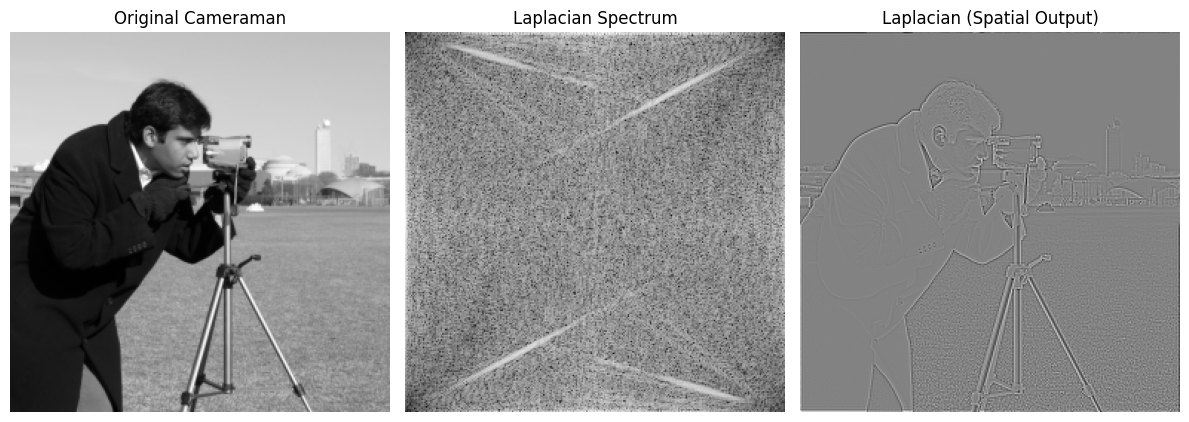

In [2]:
# Load cameraman image (already grayscale)
# image = data.camera()
image = io.imread('images/camera.png')   # the same image as data.camera(), saved in the images folder
image = resize(image, (256, 256))  # Resize for faster FFT (optional)

# Get image size
M, N = image.shape

# Generate frequency grid (centered)
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

# Compute Laplacian filter in frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

# Apply 2D FFT
F = np.fft.fft2(image)

# Apply Laplacian filter in frequency domain
F_lap = F * laplacian_filter

# Inverse FFT to get spatial result
laplacian_image = np.fft.ifft2(F_lap).real

# Plot results
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(F_lap)), cmap='gray')
plt.title('Laplacian Spectrum')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap='gray')
plt.title('Laplacian (Spatial Output)')
plt.axis('off')

plt.tight_layout()
plt.show()

In [3]:
# check the image and the filter
print("same image as data.camera() :", bool((io.imread('images/camera.png') == data.camera()).all()))
print("image :", image.shape, image.dtype, " min/max =", round(float(image.min()), 3), round(float(image.max()), 3))
print("frequencies u :", u.min(), "to", u.max(), "cycles/pixel")
print("filter at (0,0) =", float(laplacian_filter[0, 0]) + 0.0, "  most negative value =", round(float(laplacian_filter.min()), 3))
print("DC term of F (sum of the image) =", round(float(F[0, 0].real), 2), " -> after the filter =", abs(F_lap[0, 0]))
print("laplacian image : min/max =", round(float(laplacian_image.min()), 3), round(float(laplacian_image.max()), 3),
      "  mean =", round(float(laplacian_image.mean()), 6) + 0.0)
print("largest imaginary part of the inverse FFT :", float(np.abs(np.fft.ifft2(F_lap).imag).max()))

same image as data.camera() : True
image : (256, 256) float64  min/max = 0.008 0.999
frequencies u : -0.5 to 0.49609375 cycles/pixel
filter at (0,0) = 0.0   most negative value = -19.739
DC term of F (sum of the image) = 33169.18  -> after the filter = 0.0
laplacian image : min/max = -2.037 1.941   mean = 0.0
largest imaginary part of the inverse FFT : 1.2755947236554692e-15


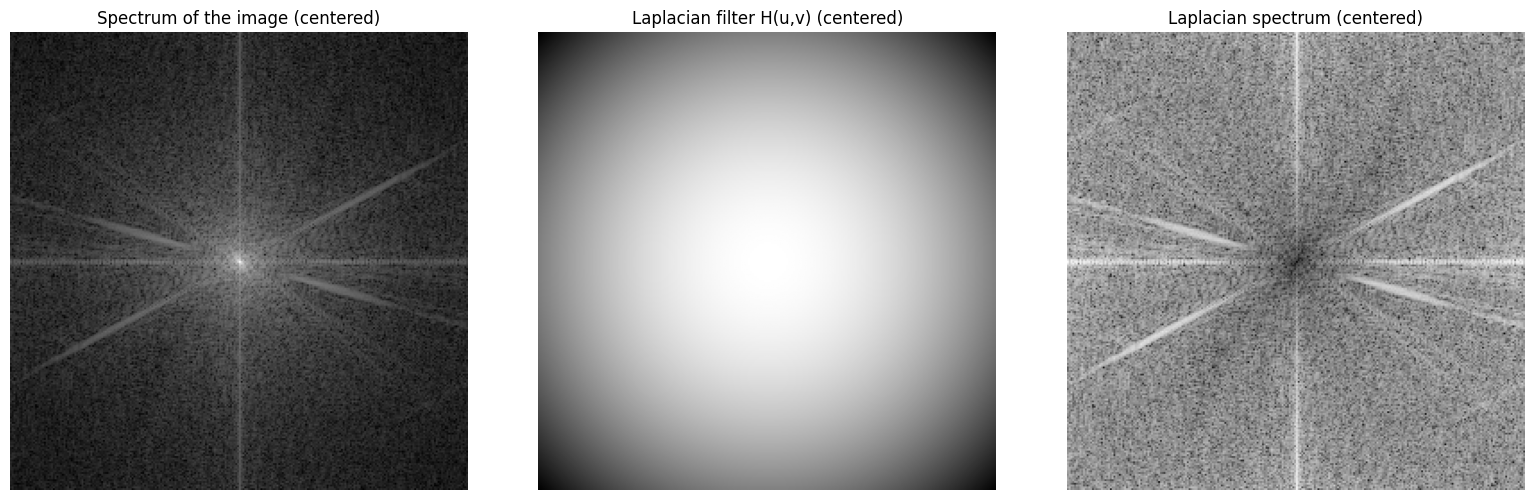

In [4]:
# fftshift moves the zero frequency to the center so the spectra are easier to read
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
ax[0].imshow(np.log(1 + np.abs(fftshift(F))), cmap='gray')
ax[0].set_title("Spectrum of the image (centered)")
ax[0].axis("off")
ax[1].imshow(fftshift(laplacian_filter), cmap='gray')
ax[1].set_title("Laplacian filter H(u,v) (centered)")
ax[1].axis("off")
ax[2].imshow(np.log(1 + np.abs(fftshift(F_lap))), cmap='gray')
ax[2].set_title("Laplacian spectrum (centered)")
ax[2].axis("off")
plt.tight_layout()
plt.show()

correlation with the 3x3 kernel result : 0.9738


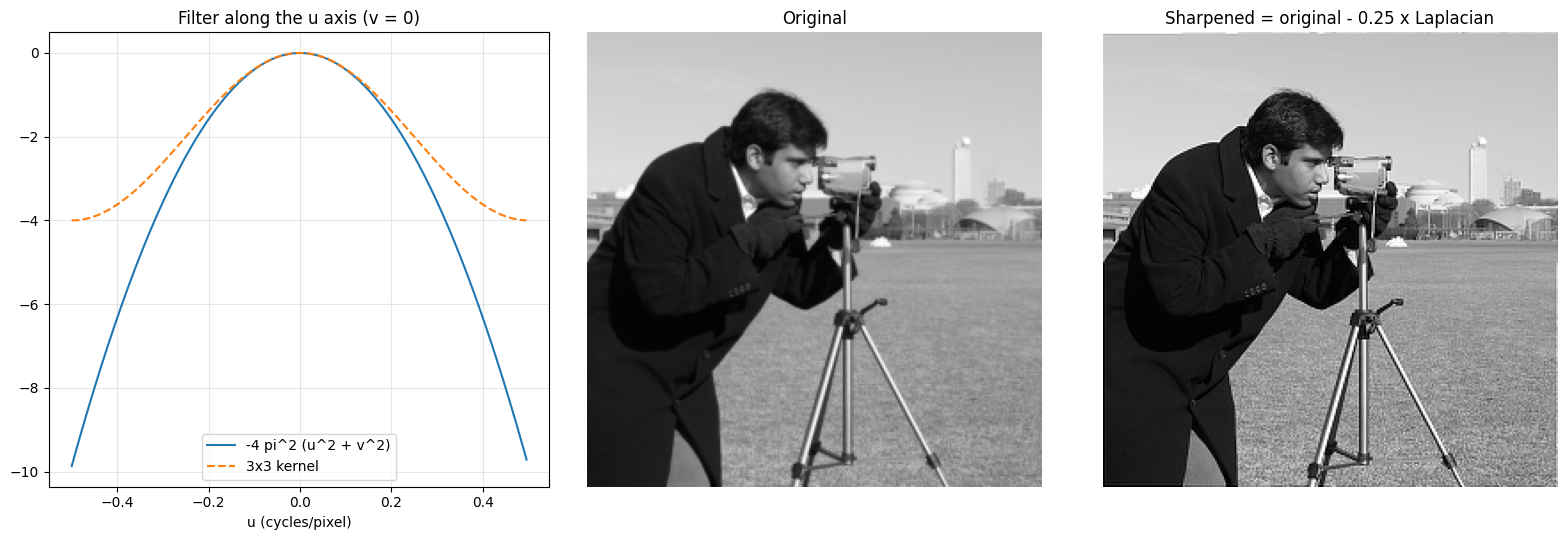

In [5]:
# compare with the discrete 3x3 Laplacian kernel applied in the same way
lap_kernel = np.array([[0, 1, 0],
                       [1, -4, 1],
                       [0, 1, 0]])
H_disc = -4 + 2 * np.cos(2 * np.pi * u) + 2 * np.cos(2 * np.pi * v)   # its frequency response
lap_disc = np.fft.ifft2(F * H_disc).real
corr = np.corrcoef(laplacian_image.ravel(), lap_disc.ravel())[0, 1]
print("correlation with the 3x3 kernel result :", round(float(corr), 4))

# sharpening : subtract the Laplacian from the image (its center is negative)
c = 0.25
sharpened = np.clip(image - c * laplacian_image, 0, 1)

fig, ax = plt.subplots(1, 3, figsize=(16, 5.5))
ax[0].plot(fftshift(u.ravel()), fftshift(laplacian_filter[:, 0]), label="-4 pi^2 (u^2 + v^2)")
ax[0].plot(fftshift(u.ravel()), fftshift(H_disc[:, 0]), '--', label="3x3 kernel")
ax[0].set_title("Filter along the u axis (v = 0)")
ax[0].set_xlabel("u (cycles/pixel)")
ax[0].legend()
ax[0].grid(alpha=0.3)
ax[1].imshow(image, cmap='gray', vmin=0, vmax=1)
ax[1].set_title("Original")
ax[1].axis("off")
ax[2].imshow(sharpened, cmap='gray', vmin=0, vmax=1)
ax[2].set_title(f"Sharpened = original - {c} x Laplacian")
ax[2].axis("off")
plt.tight_layout()
plt.show()

## 2. Student tasks

### Task 1
Using the same Cameraman image, apply the Sobel filter(s) in the frequency domain and show the results.

### Task 1 Solution – Sobel filters in the frequency domain

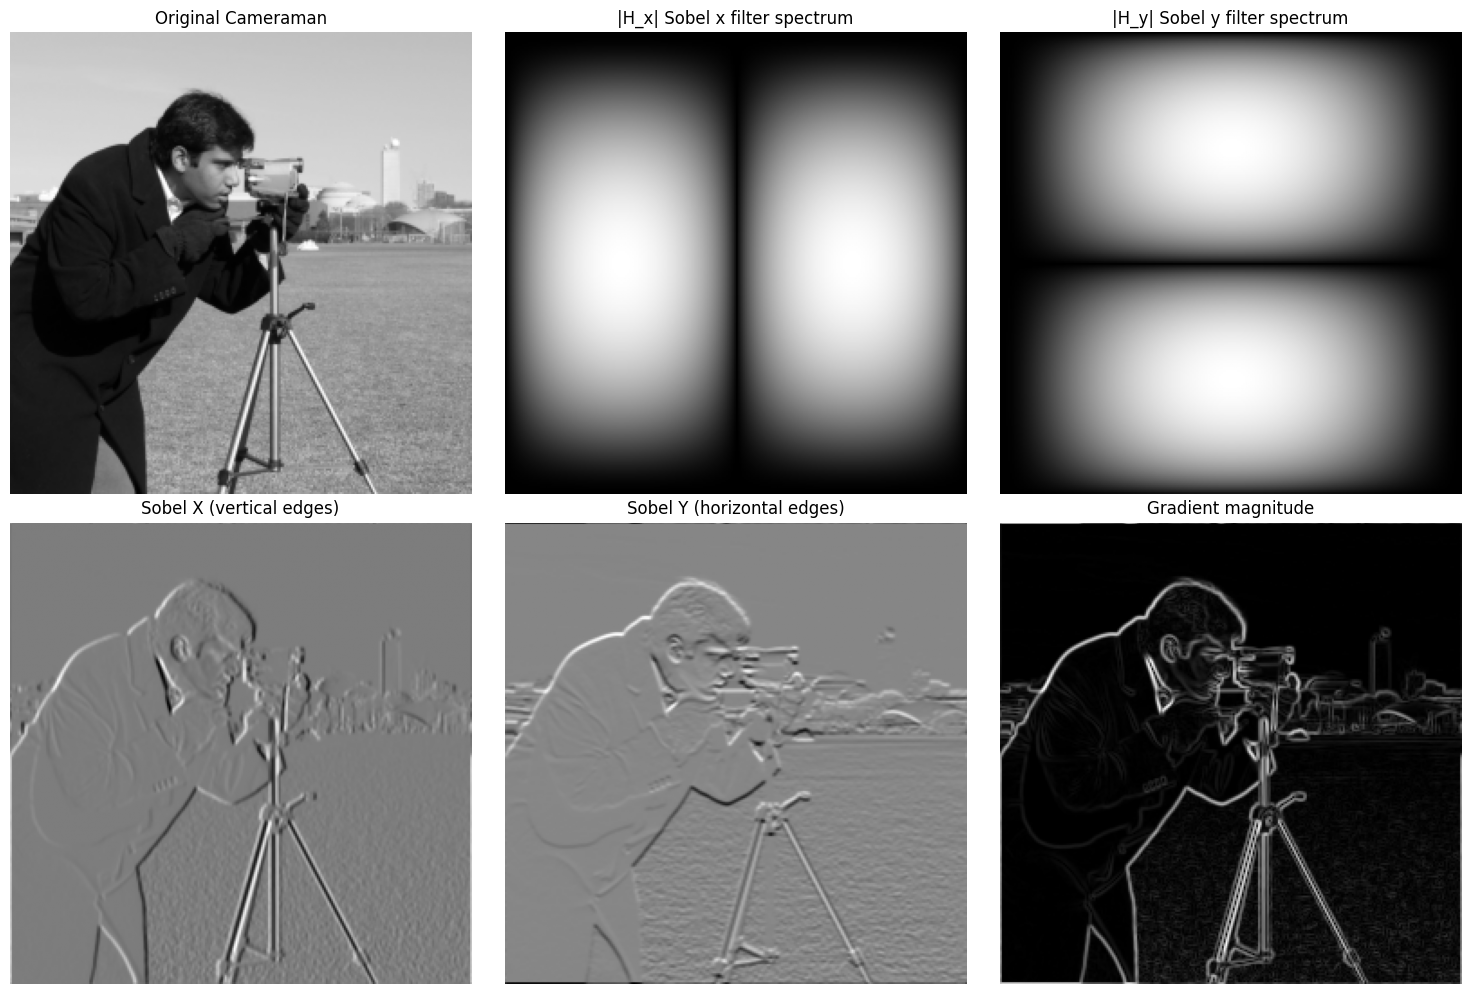

In [6]:
# Load and resize image
image = io.imread('images/camera.png')   # data.camera()
image = resize(image, (256, 256))
M, N = image.shape

# Sobel filters
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

# Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    # Find center coordinates
    cy, cx = ph // 2, pw // 2
    # Insert kernel centered at the image center
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))  # Shift before FFT to place (0,0) at top-left

# Compute FFT of image
F = fft2(image)

# FFT of centered Sobel filters (use the provided function)
H_x = center_embed_kernel(sobel_x, (M, N))
H_y = center_embed_kernel(sobel_y, (M, N))

# Multiply in the frequency domain
G_x = F * H_x
G_y = F * H_y

# Back to the spatial domain
sobel_x_image = ifft2(G_x).real
sobel_y_image = ifft2(G_y).real
magnitude = np.sqrt(sobel_x_image**2 + sobel_y_image**2)

# Plot
fig, ax = plt.subplots(2, 3, figsize=(15, 10))

ax[0, 0].imshow(image, cmap='gray')
ax[0, 0].set_title("Original Cameraman")

ax[0, 1].imshow(np.log(1 + np.abs(fftshift(H_x))), cmap='gray')
ax[0, 1].set_title("|H_x| Sobel x filter spectrum")

ax[0, 2].imshow(np.log(1 + np.abs(fftshift(H_y))), cmap='gray')
ax[0, 2].set_title("|H_y| Sobel y filter spectrum")

ax[1, 0].imshow(sobel_x_image, cmap='gray')
ax[1, 0].set_title("Sobel X (vertical edges)")

ax[1, 1].imshow(sobel_y_image, cmap='gray')
ax[1, 1].set_title("Sobel Y (horizontal edges)")

ax[1, 2].imshow(magnitude, cmap='gray')
ax[1, 2].set_title("Gradient magnitude")

for a in ax.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

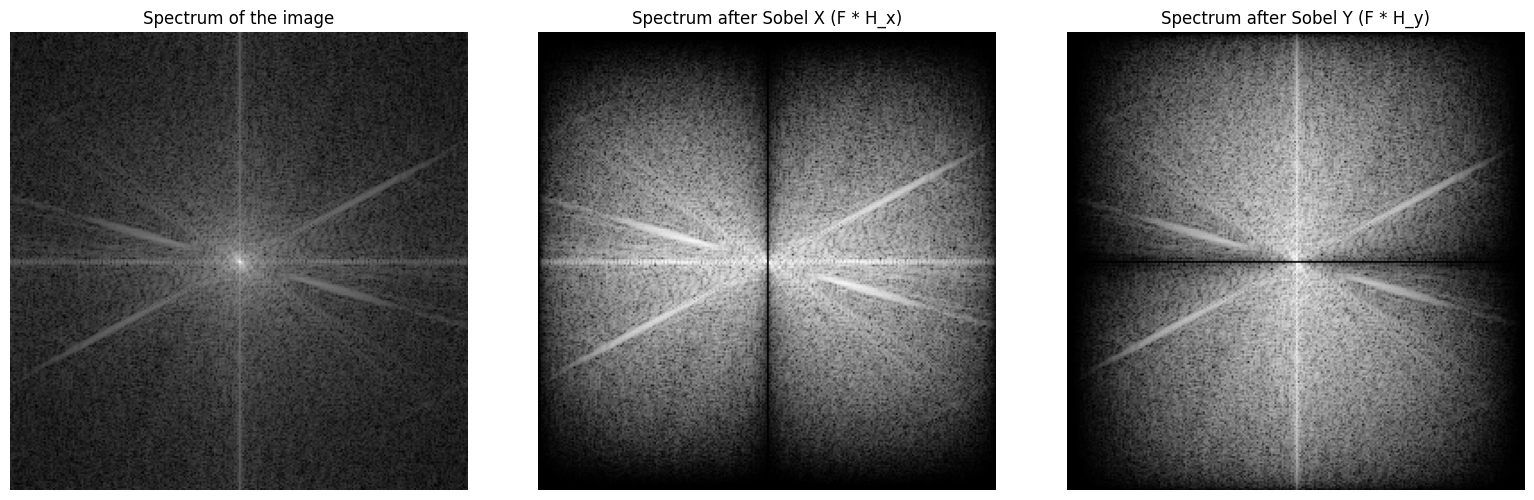

In [7]:
# spectra of the filtered images
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
ax[0].imshow(np.log(1 + np.abs(fftshift(F))), cmap='gray')
ax[0].set_title("Spectrum of the image")
ax[1].imshow(np.log(1 + np.abs(fftshift(G_x))), cmap='gray')
ax[1].set_title("Spectrum after Sobel X (F * H_x)")
ax[2].imshow(np.log(1 + np.abs(fftshift(G_y))), cmap='gray')
ax[2].set_title("Spectrum after Sobel Y (F * H_y)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

In [8]:
# check 1 : multiplying the FFTs = circular convolution in the spatial domain
from scipy.signal import convolve2d
conv_x = convolve2d(image, sobel_x, mode='same', boundary='wrap')
conv_y = convolve2d(image, sobel_y, mode='same', boundary='wrap')
print("largest difference from spatial convolution : x =", float(np.abs(sobel_x_image - conv_x).max()),
      "  y =", float(np.abs(sobel_y_image - conv_y).max()))

# check 2 : the Sobel kernels are antisymmetric, so their spectra are purely imaginary
print("largest real part of H_x :", float(np.abs(H_x.real).max()), "  of H_y :", float(np.abs(H_y.real).max()))
print("largest imaginary part left after ifft2 :", float(np.abs(ifft2(G_x).imag).max()))

# check 3 : the kernels sum to 0, so the DC term (the average brightness) is removed
print("H_x(0,0) =", abs(H_x[0, 0]), "  H_y(0,0) =", abs(H_y[0, 0]), "  peak |H| =", round(float(np.abs(H_x).max()), 3))
print("mean of Sobel X / Sobel Y :", round(float(sobel_x_image.mean()), 6) + 0.0, "/", round(float(sobel_y_image.mean()), 6) + 0.0)
print("magnitude : min/max =", round(float(magnitude.min()), 3), round(float(magnitude.max()), 3))

largest difference from spatial convolution : x = 1.7763568394002505e-15   y = 2.8622937353617317e-15
largest real part of H_x : 1.9984014443252818e-15   of H_y : 2.6645352591003757e-15
largest imaginary part left after ifft2 : 1.0818316025869532e-15
H_x(0,0) = 0.0   H_y(0,0) = 0.0   peak |H| = 8.0
mean of Sobel X / Sobel Y : 0.0 / 0.0
magnitude : min/max = 0.0 3.448


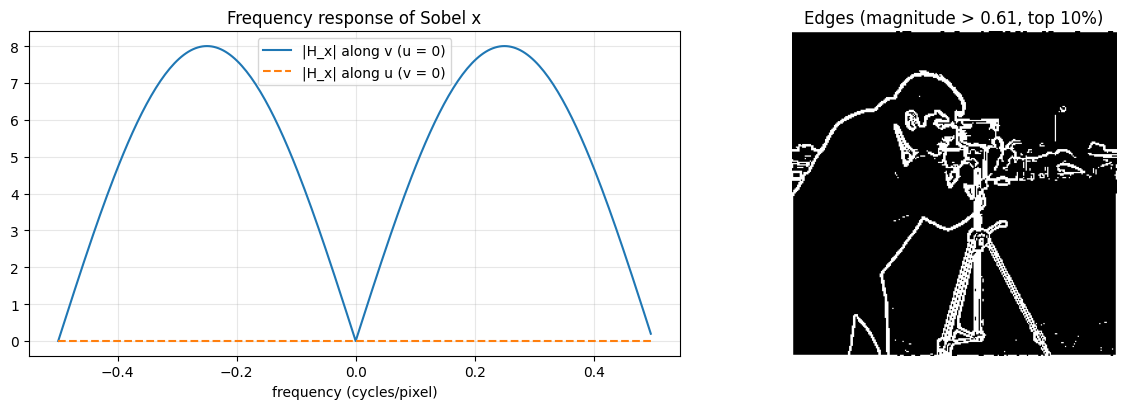

In [9]:
# the filter along one axis : Sobel x only lets through changes along x
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
v_axis = fftshift(np.fft.fftfreq(N))
ax[0].plot(v_axis, np.abs(fftshift(H_x[0, :])), label="|H_x| along v (u = 0)")
ax[0].plot(v_axis, np.abs(fftshift(H_x[:, 0])), '--', label="|H_x| along u (v = 0)")
ax[0].set_xlabel("frequency (cycles/pixel)")
ax[0].set_title("Frequency response of Sobel x")
ax[0].legend()
ax[0].grid(alpha=0.3)

# edge map : keep the strongest 10% of the gradient magnitude
thr = np.percentile(magnitude, 90)
ax[1].imshow(magnitude > thr, cmap='gray')
ax[1].set_title(f"Edges (magnitude > {thr:.2f}, top 10%)")
ax[1].axis("off")
plt.tight_layout()
plt.show()

Explanation: a convolution in the spatial domain is a multiplication in the frequency domain, so I moved the image and the two Sobel kernels to the frequency domain with the FFT, multiplied them and came back with the inverse FFT. The kernel had to be padded to the size of the image and its center moved to position (0,0), otherwise the result would be shifted. The result is identical to a spatial convolution with wrap-around borders, which is what the FFT assumes. Sobel x responds to changes along x, so it shows the vertical edges such as the tripod and the coat, Sobel y shows the horizontal edges, and the magnitude combines both. The kernels sum to 0, so the filter removes the zero frequency (the average brightness) and lets the high frequencies along one direction pass.